In [1]:
import pickle

In [2]:
with open("data/data.pickle", "rb") as p:
    data = pickle.load(p)

In [3]:
normal = data["train"][0][next((i for i, x in enumerate(data["train"][1]) if x == 0), -1)]
box = data["train"][0][next((i for i, x in enumerate(data["train"][1]) if x == 1), -1)]
inhaler = data["train"][0][next((i for i, x in enumerate(data["train"][1]) if x == 2), -1)]

In [4]:
from matplotlib.pyplot import plot, clf

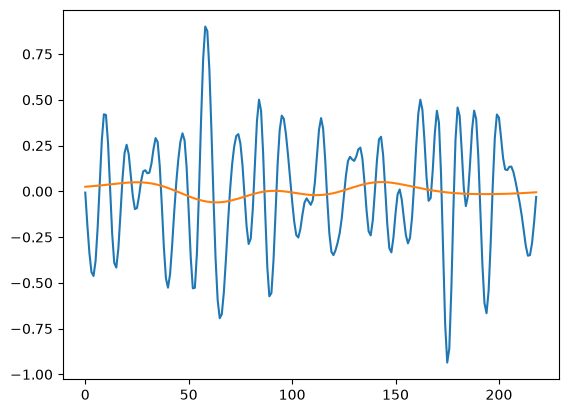

In [5]:
plot(list(range(len(normal[0]))), normal[0])
plot(list(range(len(normal[1]))), normal[1])

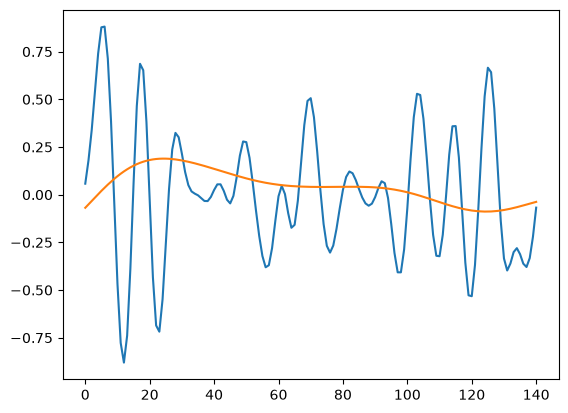

In [6]:
clf()
plot(list(range(len(box[0]))), box[0])
plot(list(range(len(box[1]))), box[1])

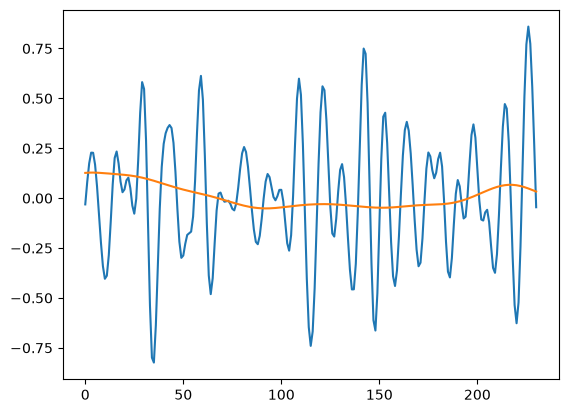

In [7]:
clf()
plot(list(range(len(inhaler[0]))), inhaler[0])
plot(list(range(len(inhaler[1]))), inhaler[1])

In [8]:
import matplotlib.pyplot as plt
from tslearn.clustering import TimeSeriesKMeans
from tslearn.preprocessing import TimeSeriesScalerMeanVariance, TimeSeriesResampler
from tslearn.utils import to_time_series_dataset

In [9]:
bvp = []
resp = []
for i in data["train"][0]:
    bvp.append(i[0])
    resp.append(i[1])
for i in data["test"][0]:
    bvp.append(i[0])
    resp.append(i[1])

In [10]:
bvp = to_time_series_dataset(bvp)
resp = to_time_series_dataset(resp)

In [11]:
bvp = TimeSeriesScalerMeanVariance().fit_transform(bvp)
resp = TimeSeriesScalerMeanVariance().fit_transform(resp)

bvp = TimeSeriesResampler(sz=80).fit_transform(bvp)
resp = TimeSeriesResampler(sz=80).fit_transform(resp)

sz = 80

In [12]:
bvp_km = TimeSeriesKMeans(n_clusters=3, metric="dtw")
y_bvp = bvp_km.fit_predict(bvp)

resp_km = TimeSeriesKMeans(n_clusters=3, metric="dtw")
y_resp = resp_km.fit_predict(resp)

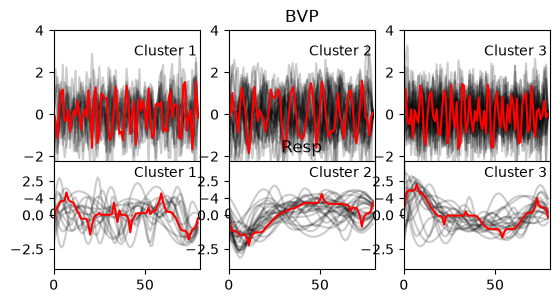

In [13]:
for yi in range(3):
    plt.subplot(2, 3, yi + 1)
    for xx in bvp[y_bvp == yi]:
        plt.plot(xx.ravel(), "k-", alpha=.2)
    plt.plot(bvp_km.cluster_centers_[yi].ravel(), "r-")
    plt.xlim(0, sz)
    plt.ylim(-4, 4)
    plt.text(0.55, 0.85,'Cluster %d' % (yi + 1),
             transform=plt.gca().transAxes)
    if yi == 1:
        plt.title("BVP")

for yi in range(3):
    plt.subplot(3, 3, 4 + yi)
    for xx in resp[y_resp == yi]:
        plt.plot(xx.ravel(), "k-", alpha=.2)
    plt.plot(resp_km.cluster_centers_[yi].ravel(), "r-")
    plt.xlim(0, sz)
    plt.ylim(-4, 4)
    plt.text(0.55, 0.85,'Cluster %d' % (yi + 1),
             transform=plt.gca().transAxes)
    if yi == 1:
        plt.title("Resp")
